# Notebook 4: Interpretabilidade, Deteção de Anomalias e Caracterização das Faixas Etárias

Neste notebook:
1. **interpretamos** o modelo: que variáveis mais pesam na previsão da faixa etária, globalmente, por faixa e em casos individuais (SHAP);
2. **detetamos perfis anómalos**: pessoas cujas respostas não batem com a faixa etária declarada;
3. **caracterizamos cada faixa etária**: o perfil típico de cada grupo.

As análises usam o modelo ordinal + regressor do Notebook 3 (secções 7.4–7.6, submissão 6, Macro F1 0,505). O modelo final (secções 7.7–7.8, submissão 7) acrescenta mais dois algoritmos ordinais e a regra da mediana; as suas previsões coincidem com as da submissão 6 em 88% das pessoas (99,5% a ≤ 1 faixa), pelo que as conclusões se mantêm.

## 1. Configuração e Carregamento dos Dados


In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore', message='IProgress not found')
import shap

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.ensemble import HistGradientBoostingRegressor
from xgboost import XGBClassifier

warnings.filterwarnings('ignore', category=FutureWarning)
plt.style.use('ggplot')

DATA_DIR = '../data'
SUBMISSIONS_DIR = '../submissions'
TARGET = 'AGE_RANGE'
RANDOM_STATE = 42
AGE_LABELS = ['15-17', '18-19', '20-24', '25-29', '30-34', '35-39', '40-44', '45-49',
              '50-54', '55-59', '60-64', '65-69', '70-74', '75-79', '80-84', '85+']

# Dados finais do Notebook 2
train_df = pd.read_csv(os.path.join(DATA_DIR, 'train_nb02.csv'), index_col='PID')
test_df = pd.read_csv(os.path.join(DATA_DIR, 'test_nb02.csv'), index_col='PID')
X = train_df.drop(columns=TARGET)
y = train_df[TARGET]
X_test = test_df[X.columns]
faixa_min = X['FAIXA_MINIMA'].values

# Validação cruzada (as mesmas 5 partes do Notebook 3) e pesos por pessoa
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
partes = list(cv.split(X, y))
pesos = compute_sample_weight('balanced', y)

# Modelo do Notebook 3 usado nas análises (secções 7.4–7.6, submissão 6): modelo ordinal + regressor, limiar 0,35
SEMENTES = [42, 1, 2, 3, 4]
LIMIAR = 0.35
MELHORES_PARAMS_GB = {'learning_rate': 0.05, 'max_leaf_nodes': 15,
                      'min_samples_leaf': 20, 'l2_regularization': 1}
PARAMS_XGB = dict(n_estimators=300, learning_rate=0.05, max_depth=4, min_child_weight=3,
                  subsample=0.8, colsample_bytree=0.5, n_jobs=-1)


def probabilidades_ordinais(X_treino, y_treino, X_prever, semente):
    """15 perguntas 'a faixa é maior do que k?' -> probabilidades das 16 faixas."""
    pesos_treino = compute_sample_weight('balanced', y_treino)
    acima = np.zeros((len(X_prever), 15))
    for k in range(15):
        modelo = XGBClassifier(**PARAMS_XGB, random_state=semente)
        modelo.fit(X_treino, (y_treino > k).astype(int), sample_weight=pesos_treino)
        acima[:, k] = modelo.predict_proba(X_prever)[:, 1]
    acima = np.minimum.accumulate(acima, axis=1)
    proba = np.column_stack([1 - acima[:, 0], acima[:, :-1] - acima[:, 1:], acima[:, -1]])
    proba = np.clip(proba, 1e-6, None)
    return proba / proba.sum(axis=1, keepdims=True)


reg = HistGradientBoostingRegressor(max_iter=500, early_stopping=True, validation_fraction=0.1,
                                    n_iter_no_change=20, random_state=RANDOM_STATE, **MELHORES_PARAMS_GB)

print(f"X: {X.shape} | y: {y.shape} | X_test: {X_test.shape}")


X: (10962, 339) | y: (10962,) | X_test: (3655, 339)


> **Conclusão:** os dados finais do Notebook 2 (10 962 pessoas de treino e 3 655 de teste, 339 features) e as definições do modelo ordinal + regressor do Notebook 3 (submissão 6) foram carregados.

## 2. Previsões Fora da Amostra do Modelo

Para a deteção de anomalias precisamos da previsão do modelo (submissão 6) para cada pessoa do treino, feita **sem que o modelo a tenha visto**: em cada uma das 5 partes da validação cruzada, os modelos são treinados nas outras 4 e preveem a parte de fora. Guardamos as 16 probabilidades, a faixa prevista (com a combinação e a correção do Notebook 3), a confiança (probabilidade máxima) e o modelo que decidiu.

Como o cálculo demora alguns minutos, o resultado é guardado em `previsoes_oof_nb04.csv` e reutilizado nas execuções seguintes.


In [2]:
FICHEIRO_OOF = os.path.join(DATA_DIR, 'previsoes_oof_nb04.csv')

if os.path.exists(FICHEIRO_OOF):
    oof = pd.read_csv(FICHEIRO_OOF, index_col='PID')
    print(f'Previsões lidas de {FICHEIRO_OOF}')
else:
    inicio = time.time()
    proba_ord = np.zeros((len(X), 16))
    for semente in SEMENTES:
        for treino, validacao in partes:
            proba_ord[validacao] += probabilidades_ordinais(X.values[treino], y.values[treino],
                                                            X.values[validacao], semente) / len(SEMENTES)
    valor_reg = cross_val_predict(reg, X, y, cv=cv, n_jobs=-1, params={'sample_weight': pesos})
    prev_reg = np.clip(np.round(valor_reg), 0, 15).astype(int)

    confiante = proba_ord.max(axis=1) >= LIMIAR
    prev_sem_correcao = np.where(confiante, proba_ord.argmax(axis=1), prev_reg)

    oof = pd.DataFrame(proba_ord, index=X.index, columns=[f'P_{k}' for k in range(16)])
    oof['REAL'] = y
    oof['PREVISTO'] = np.maximum(prev_sem_correcao, faixa_min)
    oof['CONFIANCA'] = proba_ord.max(axis=1)
    oof['DECIDIDO_POR'] = np.where(confiante, 'Ordinal', 'Regressor')
    oof.to_csv(FICHEIRO_OOF)
    print(f'Previsões calculadas em {time.time() - inicio:.0f} s e guardadas em {FICHEIRO_OOF}')

oof['ERRO'] = oof['PREVISTO'] - oof['REAL']                      # > 0: o modelo dá mais idade do que a real
print(f"Macro F1: {f1_score(oof['REAL'], oof['PREVISTO'], average='macro'):.4f}")
print(f"Acerto exato: {(oof['ERRO'] == 0).mean() * 100:.1f}% | a ≤ 1 faixa: {(oof['ERRO'].abs() <= 1).mean() * 100:.1f}%")
print(f"Decididas pelo regressor: {(oof['DECIDIDO_POR'] == 'Regressor').mean() * 100:.1f}%")
display(oof['ERRO'].value_counts().sort_index().rename('Pessoas').to_frame().T)


Previsões lidas de ../data/previsoes_oof_nb04.csv
Macro F1: 0.5051
Acerto exato: 50.0% | a ≤ 1 faixa: 88.1%
Decididas pelo regressor: 11.2%


ERRO,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6
Pessoas,2,6,6,34,142,558,2150,5481,2028,451,88,13,1,2


> **Conclusão:** as previsões fora da amostra reproduzem exatamente o modelo da secção 7.5 do Notebook 3 (Macro F1 = 0,5051; acerto exato 50,0%; 88,1% a ≤ 1 faixa; 11,2% das pessoas decididas pelo regressor). Os erros são simétricos e concentrados junto de zero: 4 178 pessoas (38%) ficam a uma faixa da real, por excesso ou por defeito. Só **64 pessoas** têm erros de 4 ou mais faixas (≥ 20 anos de diferença): 48 parecem muito mais novas do que são e 16 muito mais velhas. Estas são as primeiras candidatas a perfis anómalos (secção 4).

## 3. Interpretabilidade do Modelo (SHAP)

O **SHAP** (*SHapley Additive exPlanations*) explica cada previsão como uma soma de contribuições: para cada pessoa e cada faixa, indica quanto cada variável aumentou ou diminuiu a pontuação dessa faixa face à média. Os valores SHAP têm duas propriedades úteis:
- são **locais**: explicam a previsão de uma pessoa concreta (secção 3.4);
- agregados (média do valor absoluto em muitas pessoas), dão a **importância global** de cada variável.

O modelo ordinal (75 classificadores binários; 165 no modelo final) não é prático de explicar diretamente. Usamos por isso:
- o **XGBoost de 16 faixas** (Notebook 3, secção 7.1; Macro F1 = 0,480, próximo do modelo ordinal e com as mesmas variáveis), para a importância global e por faixa (3.1 e 3.2);
- algumas **perguntas do modelo ordinal** ("tem 55 anos ou mais?", ...), para ver o que separa as idades em cada fronteira (3.3).

Os valores SHAP são calculados pelo próprio XGBoost (`pred_contribs=True`), que implementa o mesmo algoritmo da biblioteca `shap` (TreeSHAP).

### 3.1 Importância global

Calculamos os valores SHAP numa amostra estratificada de 2000 pessoas (mesma proporção de faixas do treino). A importância de cada variável é a média do |SHAP|, somada nas 16 faixas. As colunas one-hot são juntadas à variável de origem (por exemplo, todas as `MAINSTAT_*` contam como `MAINSTAT`), para comparar variáveis e não categorias soltas.


SHAP calculado em 13 s | forma: (2000, 339, 16)


,MAINSTAT,IN15,PC1A,MARSTALEGAL,PC1C,PC1D,HH_INACT,PC1E,PC1B,HATLEVEL,IDADE_MINIMA,HH_ACT,HA1B,HHTYPE,PA7_NAC,PARTNERS,JOBSTAT,FT_PT,HA1G,N_NAO_APLICAVEL
% da importância total,6.9,5.5,5.3,4.8,4.0,3.5,3.4,3.0,2.9,2.9,2.5,2.4,2.3,1.9,1.9,1.9,1.3,1.3,1.1,1.0


As 20 variáveis mais importantes explicam 60% da importância total (de 260 variáveis)


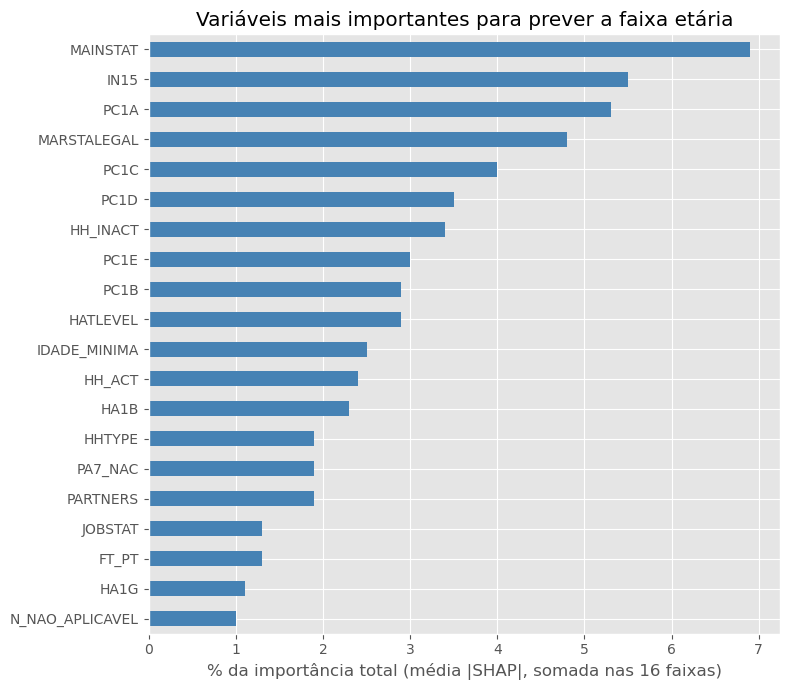

In [3]:
from xgboost import DMatrix

inicio = time.time()
xgb_16 = XGBClassifier(**{**PARAMS_XGB, 'n_estimators': 350}, random_state=RANDOM_STATE)
xgb_16.fit(X.values, y, sample_weight=pesos)

# SHAP numa amostra estratificada de 2000 pessoas (cálculo mais rápido, mesma proporção de faixas)
amostra = X.groupby(y, group_keys=False).apply(lambda g: g.sample(frac=2000 / len(X), random_state=RANDOM_STATE))
contrib = xgb_16.get_booster().predict(DMatrix(amostra.values), pred_contribs=True)   # (pessoas, faixas, features + 1)
valores_shap = contrib[:, :, :-1].transpose(0, 2, 1)                # (pessoas, features, faixas); sem a coluna da base
print(f'SHAP calculado em {time.time() - inicio:.0f} s | forma: {valores_shap.shape}')

# Importância global: média do |SHAP| em todas as pessoas, somada nas 16 faixas
importancia = pd.Series(np.abs(valores_shap).mean(axis=0).sum(axis=1), index=X.columns)

NOMINAIS = ['REGION', 'NUTS2', 'BIRTHPLACE', 'BIRTHPLACEFATH', 'BIRTHPLACEMOTH', 'CITIZEN', 'MARSTALEGAL',
            'MAINSTAT', 'JOBSTAT', 'JOBISCO', 'LOCNACE', 'HHTYPE', 'IN5', 'IN14', 'IN16', 'IN17', 'IN21',
            'IN22', 'IN44', 'IN49', 'IN62', 'IC2']


def variavel_original(coluna):
    """Junta as colunas one-hot à variável de origem (ex.: MAINSTAT_Reformado -> MAINSTAT)."""
    prefixo = coluna.split('_')[0]
    return prefixo if prefixo in NOMINAIS else coluna


importancia_var = importancia.groupby(variavel_original).sum().sort_values(ascending=False)
top20 = (importancia_var.head(20) / importancia_var.sum() * 100).round(1)
display(top20.rename('% da importância total').to_frame().T)
print(f'As 20 variáveis mais importantes explicam {top20.sum():.0f}% da importância total '
      f'(de {len(importancia_var)} variáveis)')

top20[::-1].plot.barh(figsize=(8, 7), color='steelblue')
plt.xlabel('% da importância total (média |SHAP|, somada nas 16 faixas)')
plt.title('Variáveis mais importantes para prever a faixa etária')
plt.tight_layout()
plt.show()


> **Conclusão:** a variável mais importante é a **`MAINSTAT`** (situação principal: estudante, empregado, reformado...), com 6,9% da importância total, seguida da **`MARSTALEGAL`** (estado civil, 4,8%). Isto confirma o que vimos no Notebook 1: as grandes etapas da vida (estudar, trabalhar, casar, reformar-se, enviuvar) são os sinais mais fortes da idade. Logo a seguir aparecem a `IN15` e as `PC1A`–`PC1E` (cuidados pessoais), mas, tal como a `HA1A`, estas perguntas **só são feitas a quem tem 55 anos ou mais**: "Não aplicável" corresponde exatamente a menos de 55 anos. Como as várias colunas trazem a mesma informação, o modelo reparte-a por todas. **Juntas** (`IN15`, `PC1A`–`PC1E`, `HA1B`, `HA1G`), valem cerca de **28%** da importância total: o corte dos 55 anos é, de longe, o fator mais forte. Seguem-se a composição do agregado (`HH_INACT`, `HH_ACT`, `HHTYPE`), a escolaridade (`HATLEVEL`) e a feature criada no Notebook 2 `IDADE_MINIMA` (2,5%, 11.ª). As 20 primeiras variáveis explicam 60% da importância, entre 260: o modelo concentra-se num número pequeno de sinais fortes.


### 3.2 Importância por faixa etária

A importância global mistura as 16 faixas. Para ver que variáveis distinguem cada faixa, calculamos:
- a importância (média |SHAP|) de cada variável **para cada faixa**, em percentagem do total dessa faixa (heatmap das 15 variáveis principais);
- nas pessoas de cada faixa, o **SHAP médio com sinal** dessa faixa, ou seja, as variáveis que mais aumentam a probabilidade da faixa correta. São os sinais que levam o modelo a reconhecer cada grupo.


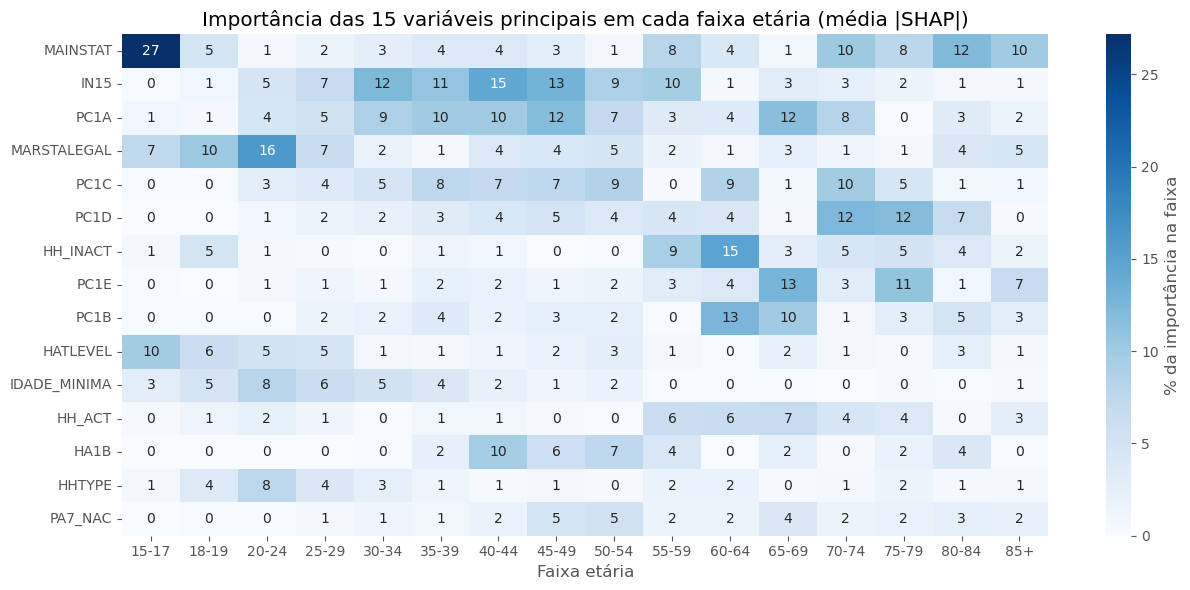

,Pessoas na amostra,1.ª,2.ª,3.ª
Faixa,,,,
15-17,38,MAINSTAT (+1.80),HATLEVEL (+0.73),MARSTALEGAL (+0.53)
18-19,31,MAINSTAT (+0.73),MARSTALEGAL (+0.41),HATLEVEL (+0.25)
20-24,73,MARSTALEGAL (+0.60),HHTYPE (+0.20),HATLEVEL (+0.18)
25-29,69,MARSTALEGAL (+0.29),HHTYPE (+0.19),IN15 (+0.16)
30-34,82,IN15 (+0.28),PC1A (+0.19),MAINSTAT (+0.14)
35-39,118,HHNBPERS_0_13_COD (+0.26),PC1A (+0.16),IN15 (+0.15)
40-44,157,IN15 (+0.26),PC1A (+0.17),MAINSTAT (+0.15)
45-49,157,PC1A (+0.24),IN15 (+0.20),PA7_NAC (+0.15)
50-54,165,MARSTALEGAL (+0.26),IN15 (+0.22),IN22 (+0.22)


In [4]:
y_amostra = y.loc[amostra.index].values

# a) Importância de cada variável para cada faixa (média |SHAP| da faixa, em % do total dessa faixa)
imp_faixa = pd.DataFrame(np.abs(valores_shap).mean(axis=0), index=X.columns, columns=AGE_LABELS)
imp_faixa = imp_faixa.groupby(variavel_original).sum()
imp_faixa = imp_faixa / imp_faixa.sum() * 100
top15 = importancia_var.head(15).index

plt.figure(figsize=(13, 6))
sns.heatmap(imp_faixa.loc[top15], annot=True, fmt='.0f', cmap='Blues', cbar_kws={'label': '% da importância na faixa'})
plt.title('Importância das 15 variáveis principais em cada faixa etária (média |SHAP|)')
plt.xlabel('Faixa etária')
plt.ylabel('')
plt.tight_layout()
plt.show()

# b) O que leva o modelo a reconhecer cada faixa: SHAP médio (com sinal) da própria faixa, nas pessoas dessa faixa
linhas = []
for k, faixa in enumerate(AGE_LABELS):
    contrib_faixa = pd.Series(valores_shap[y_amostra == k, :, k].mean(axis=0), index=X.columns)
    contrib_faixa = contrib_faixa.groupby(variavel_original).sum().sort_values(ascending=False)
    linhas.append({'Faixa': faixa, 'Pessoas na amostra': (y_amostra == k).sum(),
                   **{f'{i + 1}.ª': f'{v} ({contrib_faixa[v]:+.2f})' for i, v in enumerate(contrib_faixa.index[:3])}})
display(pd.DataFrame(linhas).set_index('Faixa'))


> **Conclusão:** as variáveis importantes mudam com a idade, acompanhando as etapas da vida:
> - **15-19 anos:** domina a `MAINSTAT` (estudante; 27% da importância na faixa 15-17), com a `HATLEVEL` (escolaridade ainda incompleta) e a `MARSTALEGAL` (solteiro);
> - **20-29 anos:** passa a dominar o estado civil (`MARSTALEGAL`, até 16% em 20-24) e o tipo de agregado (`HHTYPE`: ainda em casa dos pais ou já em casal);
> - **30-54 anos:** o sinal principal é o bloco das perguntas que só se fazem a partir dos 55 (`IN15`, `PC1A`–`E`, `HA1B`): o facto de **não** terem sido feitas indica que a pessoa tem menos de 55. Aparecem também sinais específicos: filhos com menos de 13 anos (`HHNBPERS_0_13_COD`) nos 35-39 e a menopausa (`IN22`) nos 50-54;
> - **55-64 anos:** a composição do agregado (`HH_ACT`, `HH_INACT`) e a reforma (`MAINSTAT`) são os sinais mais fortes, com `HH_INACT` a valer 15% em 60-64;
> - **65+ anos:** volta a dominar a `MAINSTAT` (reformado), juntamente com o grau de dificuldade nas tarefas de cuidado pessoal (`PC1*`). Nos 85+, o mais forte é o número de dificuldades (`N_DIFICULDADES`, feature criada no Notebook 2).
>
> As colunas `IN15`, `PC1A`–`E`, `HA1B` e `HA1G` são intercambiáveis no corte dos 55, e o modelo escolhe uma ou outra quase ao acaso (cada árvore só vê metade das colunas). A variável concreta que aparece em cada faixa acima dos 55 não deve por isso ser interpretada isoladamente; o que importa é o bloco.


### 3.3 As fronteiras do modelo ordinal

O modelo ordinal responde a 15 perguntas do tipo "a faixa é maior do que k?". Treinamos o modelo binário de 5 dessas perguntas (com os mesmos parâmetros e pesos do modelo ordinal) e calculamos os seus valores SHAP na mesma amostra. Assim vemos que variáveis separam as pessoas de cada lado de cada fronteira: 20, 35, 55, 65 e 80 anos.

Para a fronteira dos 65 anos, mostramos também o gráfico detalhado do SHAP (*beeswarm*): cada ponto é uma pessoa, a posição horizontal é o efeito da variável na previsão ("65 ou mais" à direita) e a cor é o valor da variável (vermelho = alto, azul = baixo).


,20 anos ou mais,35 anos ou mais,55 anos ou mais,65 anos ou mais,80 anos ou mais
1,MAINSTAT (11%),MARSTALEGAL (8%),HA1B (15%),HH_INACT (17%),MAINSTAT (11%)
2,MARSTALEGAL (8%),IN15 (6%),IN15 (13%),HH_ACT (14%),MARSTALEGAL (5%)
3,PARTNERS (7%),PC1A (6%),PC1C (12%),MAINSTAT (10%),PA7_NAC (4%)
4,HATLEVEL (5%),IDADE_MINIMA (4%),PC1A (12%),IN15 (7%),PC1B (3%)
5,N_NAO_APLICAVEL (4%),MAINSTAT (4%),PC1D (7%),HHNBPERS_COD (4%),PC1C (3%)
6,IDADE_MINIMA (4%),HATLEVEL (3%),PC1B (6%),PC1B (4%),HH_INACT (3%)
7,HHTYPE (3%),PC1C (3%),N_NAO_APLICAVEL (4%),PC1C (3%),PC1A (3%)
8,FAIXA_MINIMA (2%),JOBSTAT (2%),HA1C (3%),MARSTALEGAL (3%),PA1_ESTADO (3%)


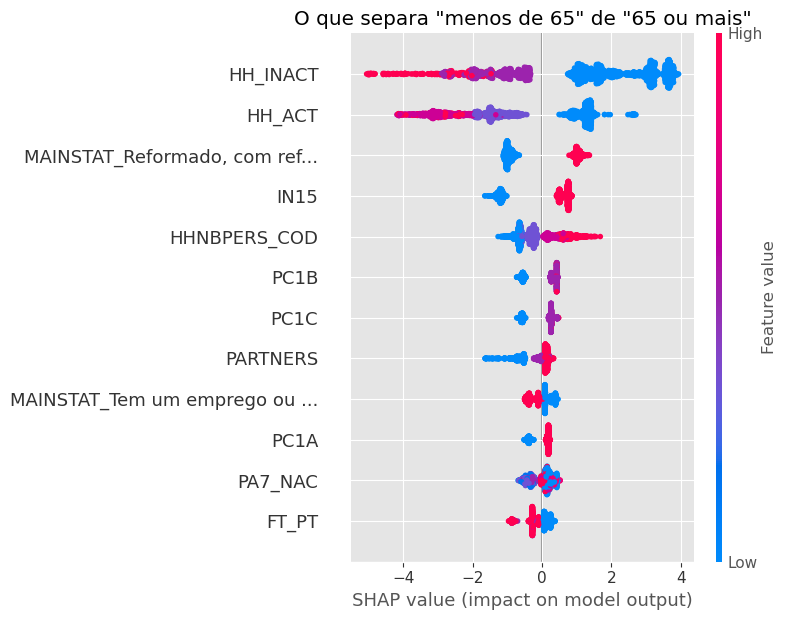

Faixa,15-17,18-19,20-24,25-29,30-34,35-39,40-44,45-49,50-54,55-59,60-64,65+
HH_ACT + HH_INACT = 0,,,,,,,,,,,,
False,205,172,399,377,449,647,859,862,905,1014,1062,807
True,2,0,0,0,0,0,0,0,0,0,0,3202


In [5]:
FRONTEIRAS = {1: '20 anos ou mais', 4: '35 anos ou mais', 8: '55 anos ou mais', 10: '65 anos ou mais', 13: '80 anos ou mais'}

shap_fronteira = {}
tabela = {}
for k, nome in FRONTEIRAS.items():
    modelo = XGBClassifier(**PARAMS_XGB, random_state=RANDOM_STATE)
    modelo.fit(X.values, (y > k).astype(int), sample_weight=pesos)
    contrib = modelo.get_booster().predict(DMatrix(amostra.values), pred_contribs=True)[:, :-1]
    shap_fronteira[k] = contrib
    imp = pd.Series(np.abs(contrib).mean(axis=0), index=X.columns).groupby(variavel_original).sum()
    imp = (imp / imp.sum() * 100).sort_values(ascending=False)
    tabela[nome] = [f'{v} ({imp[v]:.0f}%)' for v in imp.index[:8]]
display(pd.DataFrame(tabela, index=range(1, 9)))

# Gráfico detalhado da fronteira dos 65 anos (cada ponto é uma pessoa); nomes longos encurtados
amostra_grafico = amostra.rename(columns=lambda c: c if len(c) <= 30 else c[:27] + '...')
plt.figure()
shap.summary_plot(shap_fronteira[10], amostra_grafico, max_display=12, show=False)
plt.title('O que separa "menos de 65" de "65 ou mais"')
plt.tight_layout()
plt.show()

# Verificação: agregado sem nenhum membro contado em HH_ACT/HH_INACT vs. idade
sem_membros = (X['HH_ACT'] + X['HH_INACT']) == 0
display(pd.crosstab(sem_membros.rename('HH_ACT + HH_INACT = 0'),
                    y.map(lambda f: AGE_LABELS[f] if f < 11 else '65+').rename('Faixa'))[AGE_LABELS[:11] + ['65+']])


> **Conclusão:** cada fronteira do modelo ordinal usa sinais diferentes, e estes coincidem com as transições da vida:
> - **20 anos:** a situação principal (`MAINSTAT`: deixar de ser estudante), o estado civil, ter companheiro (`PARTNERS`) e a escolaridade (`HATLEVEL`);
> - **35 anos:** o estado civil e o bloco das perguntas que só se fazem a partir dos 55. Aqui o "Não aplicável" desse bloco indica "abaixo dos 55" e ajuda a afastar as pessoas mais velhas;
> - **55 anos:** quase exclusivamente o bloco de autonomia (`HA1B`, `IN15`, `PC1C`, `PC1A`...), as perguntas que só se fazem a partir dos 55 (mais de 60% da importância);
> - **65 anos:** dominam a `HH_INACT` e a `HH_ACT` (31% juntas), seguidas da reforma (`MAINSTAT`). A tabela de verificação mostra porquê: estas variáveis só contam os membros do agregado com **menos de 65 anos**, e por isso **somam 0 em 3202 pessoas, todas com 65 anos ou mais** (as 2 únicas exceções têm 15-17 anos). É um **segundo corte**, tão forte como o dos 55. O contrário não se verifica: 807 pessoas com 65+ vivem com pessoas mais novas e não são apanhadas por esta regra. O gráfico detalhado confirma que valores baixos (azul) de `HH_INACT`/`HH_ACT` empurram fortemente para "65 ou mais", tal como a reforma;
> - **80 anos:** não há nenhum sinal dominante (o 1.º, `MAINSTAT`, vale só 11%). A importância reparte-se pelo grau de dificuldade nas tarefas pessoais (`PC1B`, `PC1C`), a viuvez e a vacinação (`PA1_ESTADO`). É por isso que as faixas acima dos 65 são as mais difíceis de distinguir entre si (F1 de 0,31–0,38).

### 3.4 Explicação de casos individuais

O SHAP também explica previsões individuais: o gráfico *waterfall* parte do valor médio do modelo para a faixa prevista (em baixo, *E[f(X)]*) e mostra como cada resposta da pessoa o aumenta (vermelho) ou diminui (azul) até ao valor final (em cima, *f(x)*). Para cada pessoa, o XGBoost é treinado **sem ela** (nas 4 partes da validação cruzada em que não está), para que a explicação seja a de uma previsão verdadeira e não de um caso já visto no treino.

Analisamos dois casos:
1. a pessoa de 60-64 corretamente prevista com maior confiança;
2. o erro de 4 ou mais faixas com maior confiança (o modelo dá muito menos idade do que a real).

Caso 1 — previsão certa | PID 3905 | real: 60-64 | previsto: 60-64 | confiança: 0.95


,SEX,MARSTALEGAL,MAINSTAT,HATLEVEL,HHTYPE,HHNBPERS_COD,HH_ACT,HH_INACT,HA1A,N_DOENCAS,N_DIFICULDADES,IDADE_MINIMA
PID,,,,,,,,,,,,
3905.0,Mulher,Solteiro,Tem um emprego ou trabalho (inc. trabalhador f...,Doutoramento,Agregado unipessoal,1.0,1.0,0.0,Nenhuma dificuldade,8,1,61.0


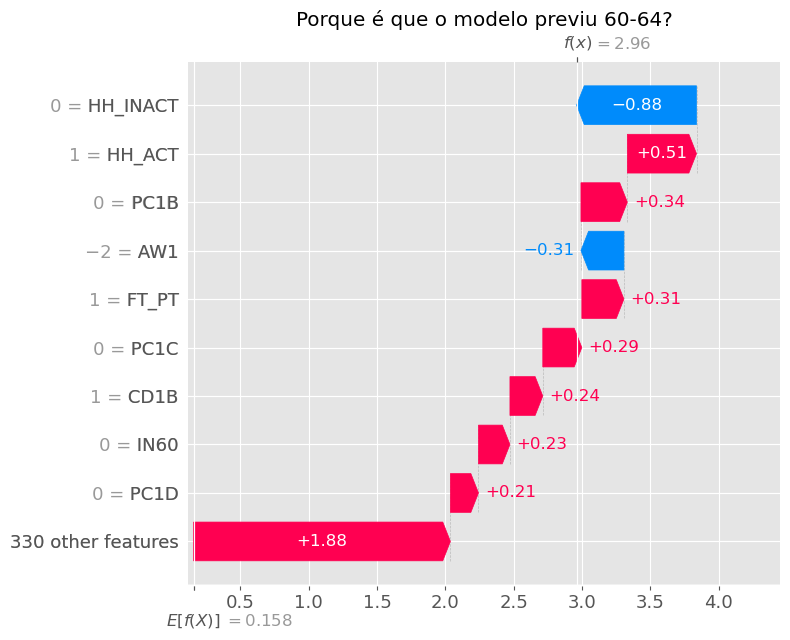

Caso 2 — erro grande | PID 1293 | real: 85+ | previsto: 65-69 | confiança: 0.86


,SEX,MARSTALEGAL,MAINSTAT,HATLEVEL,HHTYPE,HHNBPERS_COD,HH_ACT,HH_INACT,HA1A,N_DOENCAS,N_DIFICULDADES,IDADE_MINIMA
PID,,,,,,,,,,,,
1293.0,Mulher,Divorciado,Tem um emprego ou trabalho (inc. trabalhador f...,Licenciatura pré-bolonha ou mestrado 2º ciclo,Agregado unipessoal,1.0,0.0,0.0,Nenhuma dificuldade,4,0,40.0


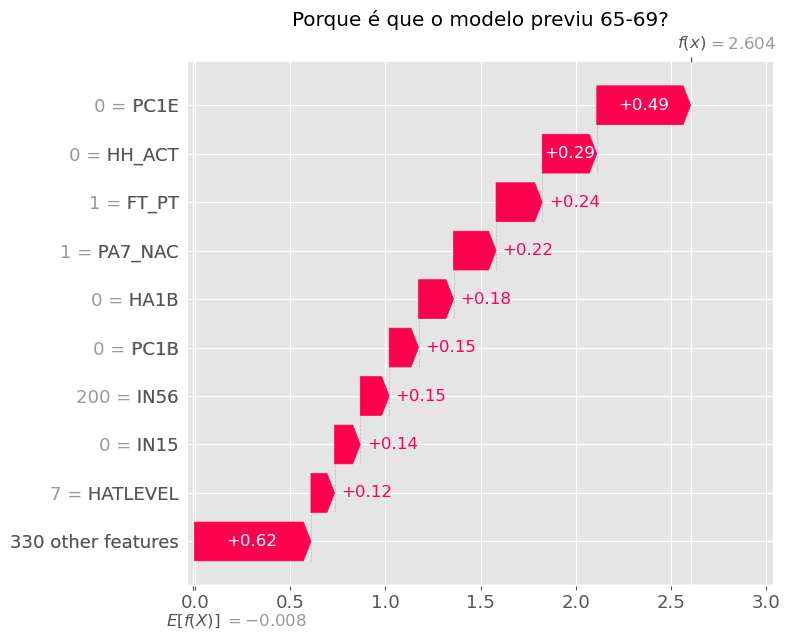

In [6]:
VARIAVEIS_PERFIL = ['SEX', 'MARSTALEGAL', 'MAINSTAT', 'HATLEVEL', 'HHTYPE', 'HHNBPERS_COD', 'HH_ACT', 'HH_INACT',
                    'HA1A', 'N_DOENCAS', 'N_DIFICULDADES', 'IDADE_MINIMA']
nomes_curtos = [c if len(c) <= 40 else c[:37] + '...' for c in X.columns]
originais = pd.read_csv(os.path.join(DATA_DIR, 'train_nb01.csv'), index_col='PID')   # respostas em texto (Notebook 1)


def explicar(pid, titulo):
    """Explica a previsão de uma pessoa com um XGBoost treinado SEM ela (as 4 partes onde não está)."""
    parte = next(i for i, (_, v) in enumerate(partes) if X.index[v].isin([pid]).any())
    treino = partes[parte][0]
    modelo = XGBClassifier(**{**PARAMS_XGB, 'n_estimators': 350}, random_state=RANDOM_STATE)
    modelo.fit(X.values[treino], y.values[treino], sample_weight=compute_sample_weight('balanced', y.values[treino]))

    linha = oof.loc[pid]
    faixa = int(linha['PREVISTO'])
    contrib = modelo.get_booster().predict(DMatrix(X.loc[[pid]].values), pred_contribs=True)[0, faixa]
    print(f"{titulo} | PID {int(pid)} | real: {AGE_LABELS[int(linha['REAL'])]} | previsto: {AGE_LABELS[faixa]} "
          f"| confiança: {linha['CONFIANCA']:.2f}")
    display(originais.loc[[pid], VARIAVEIS_PERFIL[:-3]].join(X.loc[[pid], VARIAVEIS_PERFIL[-3:]]))
    explicacao = shap.Explanation(values=contrib[:-1], base_values=contrib[-1],
                                  data=X.loc[pid].values, feature_names=nomes_curtos)
    plt.figure()
    shap.plots.waterfall(explicacao, max_display=10, show=False)
    plt.title(f'Porque é que o modelo previu {AGE_LABELS[faixa]}?')
    plt.tight_layout()
    plt.show()


# Caso 1: uma pessoa de 60-64 bem prevista, com a confiança mais alta
certos = oof[(oof['REAL'] == 10) & (oof['PREVISTO'] == 10)]
explicar(certos['CONFIANCA'].idxmax(), 'Caso 1 — previsão certa')

# Caso 2: o maior erro com mais confiança (o modelo dá muito menos idade do que a real)
errados = oof[oof['ERRO'] <= -4]
explicar(errados['CONFIANCA'].idxmax(), 'Caso 2 — erro grande')


> **Conclusão:** os dois casos mostram como o modelo "raciocina".
>
> **Caso 1 (PID 3905, real e previsto 60-64, confiança 0,95):** mulher solteira, com doutoramento, empregada e a viver sozinha. As perguntas de autonomia (`PC1B`, `PC1C`, `PC1D`) foram feitas (portanto tem 55+) e responde sem dificuldades. `HH_ACT = 1`: ela própria ainda conta como pessoa ativa com menos de 65 anos (+0,51). Trabalha a tempo inteiro (`FT_PT`, +0,31). A combinação "55+, mas ainda a trabalhar e contada no agregado ativo" aponta diretamente para 55-64. O único sinal contrário é `HH_INACT = 0` (−0,88), mas não chega para mudar a decisão.
>
> **Caso 2 (PID 1293, real 85+, previsto 65-69, confiança 0,86):** mulher divorciada, licenciada, **empregada a tempo inteiro**, a viver sozinha e **sem nenhuma dificuldade** nas tarefas do dia a dia. As perguntas de autonomia foram feitas (`PC1E`, `HA1B`, `IN15`, `PC1B`) e `HH_ACT = 0` → o modelo sabe que tem 65+. Mas tudo o resto (emprego a tempo inteiro, nenhuma limitação, escolaridade alta) descreve uma pessoa no início da reforma, e não uma de 85+. O modelo escolhe por isso a faixa mais nova possível acima dos 65. Não é uma falha do modelo: é um **perfil anómalo**, que não bate com a faixa declarada. Pode ser uma pessoa excecional ou um erro no registo da idade, e é analisado na secção 4.


## 4. Deteção de Anomalias

Procuramos pessoas cujo perfil não bate com a faixa etária declarada, com duas abordagens complementares:
1. **incoerências lógicas** (4.1): regras de bom senso aplicadas diretamente às respostas, sem modelo;
2. **anomalias segundo o modelo** (4.2): pessoas cujas respostas, no seu conjunto, apontam com grande confiança para uma faixa muito diferente da real.

### 4.1 Incoerências lógicas

Definimos regras que identificam combinações de respostas impossíveis ou muito improváveis para a faixa etária declarada, classificadas por gravidade:
- **Impossível:** contradiz a própria idade (ex.: idade mínima, calculada no Notebook 2 a partir de idades declaradas noutras perguntas, acima da faixa real);
- **Muito improvável:** legalmente possível, mas quase nunca observado (ex.: menor de 18 casado ou a viver sozinho, curso superior antes da idade normal de conclusão);
- **Raro:** possível, mas fora do comum (ex.: estudante com 80 ou mais, empregado com 85 ou mais).

As respostas em texto são lidas dos dados do Notebook 1.


In [7]:
REGRAS = {
    'Idade declarada acima da faixa (FAIXA_MINIMA > real)':
        ('Impossível', X['FAIXA_MINIMA'] > y),
    'Menor de 18 casado, divorciado ou viúvo':
        ('Muito improvável', (y == 0) & originais['MARSTALEGAL'].isin(['Casado', 'Divorciado', 'Viúvo'])),
    'Menor de 18 a viver sozinho':
        ('Muito improvável', (y == 0) & (originais['HHTYPE'] == 'Agregado unipessoal')),
    'Licenciatura (1.º ciclo), bacharelato ou CTeSP antes dos 20':
        ('Muito improvável', (y <= 1) & originais['HATLEVEL'].isin(
            ['Bacharelato ou licenciatura 1º ciclo', 'C.T.Superior Profissional', 'Licenciatura pré-bolonha ou mestrado 2º ciclo'])),
    'Doutoramento antes dos 25':
        ('Muito improvável', (y <= 2) & (originais['HATLEVEL'] == 'Doutoramento')),
    'Estudante com 80 ou mais':
        ('Raro', (y >= 14) & originais['MAINSTAT'].str.startswith('Aluno')),
    'Empregado com 85 ou mais':
        ('Raro', (y == 15) & originais['MAINSTAT'].str.startswith('Tem um emprego')),
}

resumo = pd.DataFrame([{'Regra': regra, 'Gravidade': gravidade, 'Pessoas': mascara.sum(),
                        'PID': [int(p) for p in X.index[mascara]]}
                       for regra, (gravidade, mascara) in REGRAS.items()]).set_index('Regra')
display(resumo)

anomalias_logicas = pd.Series(False, index=X.index)
for _, mascara in REGRAS.values():
    anomalias_logicas |= mascara
print(f'Pessoas com pelo menos uma incoerência: {anomalias_logicas.sum()} ({anomalias_logicas.mean() * 100:.2f}%)')

# Detalhe: as respostas destas pessoas e o que o modelo previu
detalhe = originais.loc[anomalias_logicas, ['SEX', 'MARSTALEGAL', 'MAINSTAT', 'HATLEVEL', 'HHTYPE']].copy()
detalhe['MAINSTAT'] = detalhe['MAINSTAT'].str[:25]
detalhe['IDADE_MINIMA'] = X.loc[anomalias_logicas, 'IDADE_MINIMA']
detalhe['Real'] = [AGE_LABELS[f] for f in y[anomalias_logicas]]
detalhe['Previsto'] = [AGE_LABELS[f] for f in oof.loc[anomalias_logicas, 'PREVISTO']]
detalhe.index = detalhe.index.astype(int)
display(detalhe)

# Origem da idade mínima nos 4 casos impossíveis (variáveis que funcionam como idades declaradas, Notebook 2)
impossiveis = X.index[REGRAS['Idade declarada acima da faixa (FAIXA_MINIMA > real)'][1]]
idades = X.loc[impossiveis, ['IN2', 'IN3', 'IN4', 'IN26', 'IN45', 'IN47']].copy()
idades['IN24 + 15'] = np.where(X.loc[impossiveis, 'IN24'] >= 0, X.loc[impossiveis, 'IN24'] + 15, -1)
idades = idades.replace(-1, np.nan)
idades['Real'] = [AGE_LABELS[f] for f in y[impossiveis]]
idades.index = idades.index.astype(int)
display(idades)


,Gravidade,Pessoas,PID
Regra,,,
Idade declarada acima da faixa (FAIXA_MINIMA > real),Impossível,4,"[9151, 11385, 554, 8743]"
"Menor de 18 casado, divorciado ou viúvo",Muito improvável,1,[14056]
Menor de 18 a viver sozinho,Muito improvável,2,"[14287, 11217]"
"Licenciatura (1.º ciclo), bacharelato ou CTeSP antes dos 20",Muito improvável,5,"[7950, 1498, 14025, 12659, 11256]"
Doutoramento antes dos 25,Muito improvável,1,[3930]
Estudante com 80 ou mais,Raro,1,[13931]
Empregado com 85 ou mais,Raro,2,"[1293, 13301]"


Pessoas com pelo menos uma incoerência: 16 (0.15%)


,SEX,MARSTALEGAL,MAINSTAT,HATLEVEL,HHTYPE,IDADE_MINIMA,Real,Previsto
PID,,,,,,,,
7950,Homem,Solteiro,"Aluno, estudante, ou em e",Bacharelato ou licenciatura 1º ciclo,Pai ou mãe com pelo menos um filho < 25 anos,15.0,18-19,20-24
1498,Homem,Solteiro,Desempregado,Bacharelato ou licenciatura 1º ciclo,Pai ou mãe com pelo menos um filho < 25 anos,15.0,18-19,20-24
9151,Mulher,Casado,Tem um emprego ou trabalh,Secundário,Casal com todos os filhos >= 25 anos,65.0,45-49,65-69
14056,Homem,Casado,"Aluno, estudante, ou em e",Básico 1º e 2º ciclo,Casal com pelo menos um filho < 25 anos,15.0,15-17,15-17
14025,Mulher,Solteiro,Desempregado,C.T.Superior Profissional,Outro tipo de agregado,17.0,18-19,20-24
11385,Mulher,Solteiro,"Aluno, estudante, ou em e",Básico 3º ciclo,Outro tipo de agregado,32.0,25-29,30-34
12659,Mulher,Solteiro,"Aluno, estudante, ou em e",C.T.Superior Profissional,Casal com pelo menos um filho < 25 anos,16.0,18-19,20-24
13931,Mulher,Solteiro,"Aluno, estudante, ou em e",Licenciatura pré-bolonha ou mestrado 2º ciclo,Outro tipo de agregado,15.0,85+,85+
14287,Homem,Solteiro,"Aluno, estudante, ou em e",Básico 3º ciclo,Agregado unipessoal,15.0,15-17,18-19


,IN2,IN3,IN4,IN26,IN45,IN47,IN24 + 15,Real
PID,,,,,,,,
9151,NaN,NaN,NaN,NaN,NaN,NaN,65.0,45-49
11385,NaN,NaN,NaN,32.0,NaN,14.0,22.0,25-29
554,NaN,NaN,NaN,2.0,NaN,NaN,31.0,15-17
8743,NaN,NaN,NaN,4.0,NaN,17.0,27.0,20-24


> **Conclusão:** 16 pessoas (0,15%) têm pelo menos uma incoerência lógica com a faixa declarada.
>
> **Impossíveis (4):** a idade mínima, calculada a partir de outras respostas, ultrapassa a faixa declarada. Em três dos casos, a origem é o tempo desde a última gravidez (`IN24`):
> - **PID 9151** (45-49): última gravidez há 50 anos;
> - **PID 554** (15-17): há 16 anos;
> - **PID 8743** (20-24): há 12 anos.
>
> No quarto, o **PID 11385** (25-29), é a `IN26`, uma idade declarada de 32 anos. O modelo, **antes da correção**, já dá mais idade aos PID 554 (25-29, apenas 1,5% de probabilidade para 15-17) e 8743 (25-29), o que reforça que são erros de registo ou de resposta.
>
> **Muito improváveis (9):**
> - um menor de 18 casado (PID 14056);
> - dois menores de 18 a viver sozinhos (PID 14287 e 11217);
> - cinco pessoas de 18-19 com curso superior (licenciatura de 1.º ciclo ou CTeSP), todas previstas em 20-24;
> - uma pessoa de 20-24 com doutoramento, divorciada e com filhos (PID 3930), que o modelo prevê em **40-44**.
>
> **Raros (3):** uma estudante de 85+ com mestrado (PID 13931) e duas pessoas de 85+ empregadas (PID 1293 e 13301). O modelo prevê-as em 65-69 e 55-59, respetivamente.
>
> As regras são simples e fáceis de justificar, mas só apanham contradições evidentes numa ou duas variáveis. A secção 4.2 procura perfis anómalos no conjunto das respostas.


### 4.2 Anomalias segundo o modelo

Para cada pessoa, usamos as previsões fora da amostra (secção 2) para calcular a **probabilidade que o modelo dá à faixa declarada ou às suas vizinhas** (± 1 faixa, cerca de ± 5 anos): `P_DECLARADA`. Confundir faixas vizinhas é normal (a fronteira entre 64 e 65 anos é ténue); um valor muito baixo significa que o **conjunto das respostas** é típico de uma idade muito diferente da declarada.

Consideramos anómalas as pessoas com `P_DECLARADA` < 0,05: o modelo dá-lhes menos de 5% de hipóteses de terem a idade declarada (± 5 anos).


Anomalias segundo o modelo (P_DECLARADA < 0.05): 36 (0.33%)
  parecem mais novas do que a faixa declarada: 20 | parecem mais velhas: 16


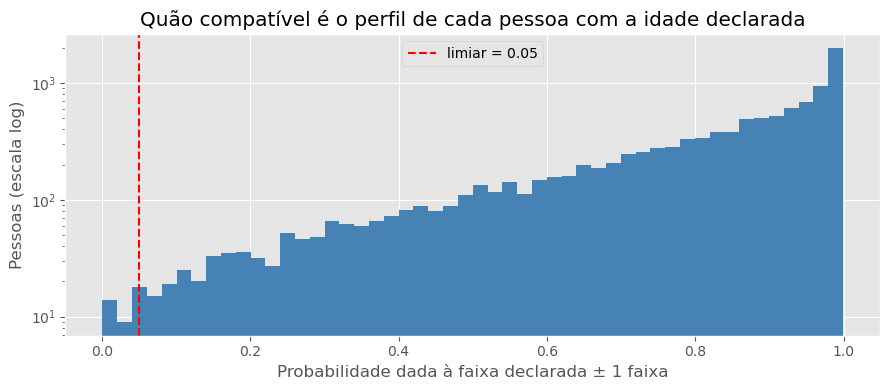

,SEX,MARSTALEGAL,MAINSTAT,HHTYPE,Real,Previsto,P_DECLARADA,Incoerência lógica (4.1)
PID,,,,,,,,
13301,Homem,Casado,Tem um emprego ou trabalh,Outro tipo de agregado,85+,55-59,0.001,Sim
1293,Mulher,Divorciado,Tem um emprego ou trabalh,Agregado unipessoal,85+,65-69,0.001,Sim
10122,Mulher,Solteiro,"Aluno, estudante, ou em e",Casal com pelo menos um f,30-34,20-24,0.002,
874,Mulher,Casado,Desempregado,Casal sem filhos,20-24,50-54,0.003,
13435,Mulher,Casado,"Reformado, com reforma an",Agregado unipessoal,75-79,50-54,0.003,
8653,Mulher,Casado,Tem um emprego ou trabalh,Casal com todos os filhos,75-79,55-59,0.005,
12497,Homem,Solteiro,"Aluno, estudante, ou em e",Casal com pelo menos um f,20-24,15-17,0.006,
12117,Mulher,Divorciado,Tem um emprego ou trabalh,Casal com pelo menos um f,20-24,40-44,0.008,
10646,Homem,Casado,"Reformado, com reforma an",Casal sem filhos,80-84,50-54,0.009,


In [8]:
LIMIAR_ANOMALIA = 0.05
proba = oof[[f'P_{k}' for k in range(16)]].values
real = oof['REAL'].values

# Probabilidade que o modelo dá à faixa declarada ou às vizinhas (± 1 faixa, ~5 anos)
oof['P_DECLARADA'] = [proba[i, max(0, real[i] - 1):real[i] + 2].sum() for i in range(len(real))]
anomalias_modelo = oof['P_DECLARADA'] < LIMIAR_ANOMALIA
print(f'Anomalias segundo o modelo (P_DECLARADA < {LIMIAR_ANOMALIA}): {anomalias_modelo.sum()} '
      f'({anomalias_modelo.mean() * 100:.2f}%)')
print(f"  parecem mais novas do que a faixa declarada: {(anomalias_modelo & (oof['ERRO'] < 0)).sum()} | "
      f"parecem mais velhas: {(anomalias_modelo & (oof['ERRO'] > 0)).sum()}")

plt.figure(figsize=(9, 4))
plt.hist(oof['P_DECLARADA'], bins=50, color='steelblue')
plt.axvline(LIMIAR_ANOMALIA, color='red', linestyle='--', label=f'limiar = {LIMIAR_ANOMALIA}')
plt.yscale('log')
plt.xlabel('Probabilidade dada à faixa declarada ± 1 faixa')
plt.ylabel('Pessoas (escala log)')
plt.title('Quão compatível é o perfil de cada pessoa com a idade declarada')
plt.legend()
plt.tight_layout()
plt.show()

# As pessoas anómalas, da mais anómala para a menos
lista = originais.loc[anomalias_modelo, ['SEX', 'MARSTALEGAL', 'MAINSTAT', 'HHTYPE']].copy()
lista['MAINSTAT'] = lista['MAINSTAT'].str[:25]
lista['HHTYPE'] = lista['HHTYPE'].str[:25]
lista['Real'] = [AGE_LABELS[f] for f in oof.loc[anomalias_modelo, 'REAL']]
lista['Previsto'] = [AGE_LABELS[f] for f in oof.loc[anomalias_modelo, 'PREVISTO']]
lista['P_DECLARADA'] = oof.loc[anomalias_modelo, 'P_DECLARADA'].round(3)
lista['Incoerência lógica (4.1)'] = anomalias_logicas[anomalias_modelo].map({True: 'Sim', False: ''})
lista.index = lista.index.astype(int)
display(lista.sort_values('P_DECLARADA'))


> **Conclusão:** 36 pessoas (0,33%) têm um perfil muito pouco compatível com a faixa declarada: o modelo, sem as ter visto, dá-lhes menos de 5% de probabilidade de estarem na sua faixa ou nas vizinhas. Destas, 20 parecem mais novas do que a idade declarada e 16 mais velhas. O histograma mostra que são casos extremos: a grande maioria das pessoas tem valores acima de 0,5. Os casos mais fortes são:
> - pessoas de 75+ previstas em 50-59 (PID 13435, 8653, 10646, 1265);
> - jovens de 20-24 previstos em 40-54 (PID 874, 12117);
> - adultos de 50-54 com perfil típico de 25-29 (PID 7191, 2556).
>
> Só **2 das 36** coincidem com as regras da secção 4.1, ambas pessoas de 85+ ainda empregadas (PID 13301 e 1293). As duas abordagens são complementares: as regras apanham contradições pontuais numa ou duas respostas; o modelo apanha perfis cujo **conjunto** de respostas é típico de outra idade.


### 4.3 Análise dos casos anómalos

Uma anomalia pode ter três origens:
- **artefacto do modelo:** o modelo engana-se por uma limitação técnica, e o perfil da pessoa não tem nada de estranho;
- **provável erro de registo:** várias respostas contradizem a idade declarada;
- **pessoa excecional:** o perfil é real, mas muito raro para a idade.

Verificamos primeiro dois padrões encontrados na lista da secção 4.2 (a resposta "Sem resposta" no bloco das perguntas feitas a partir dos 55 anos, e a menopausa declarada antes dos 40) e analisamos depois dois casos com o SHAP.


Idade,55 ou mais,Menos de 55
"""Sem resposta"" no bloco dos 55",,
False,6042,4877
True,43,0


Anomalias da 4.2 explicadas por "Sem resposta" no bloco dos 55: 4 (PID [10646, 13435, 1265, 13291])
Menopausa declarada antes dos 40: 3 (PID [874, 905, 8743], faixas ['20-24', '25-29', '20-24'])
Anomalia 1 — 20-24 com menopausa | PID 874 | real: 20-24 | previsto: 50-54 | confiança: 0.92


,SEX,MARSTALEGAL,MAINSTAT,HATLEVEL,HHTYPE,HHNBPERS_COD,HH_ACT,HH_INACT,HA1A,N_DOENCAS,N_DIFICULDADES,IDADE_MINIMA
PID,,,,,,,,,,,,
874.0,Mulher,Casado,Desempregado,Básico 1º e 2º ciclo,Casal sem filhos,2.0,0.0,1.0,Não aplicável,3,0,15.0


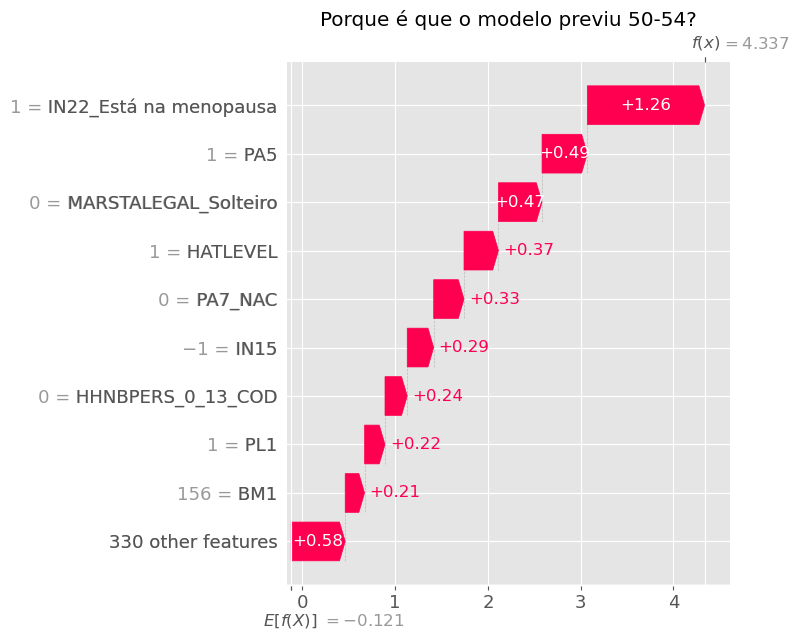

Anomalia 2 — 85+ a trabalhar | PID 13301 | real: 85+ | previsto: 55-59 | confiança: 0.64


,SEX,MARSTALEGAL,MAINSTAT,HATLEVEL,HHTYPE,HHNBPERS_COD,HH_ACT,HH_INACT,HA1A,N_DOENCAS,N_DIFICULDADES,IDADE_MINIMA
PID,,,,,,,,,,,,
13301.0,Homem,Casado,Tem um emprego ou trabalho (inc. trabalhador f...,Básico 3º ciclo,Outro tipo de agregado,4.0,2.0,0.0,Nenhuma dificuldade,0,0,25.0


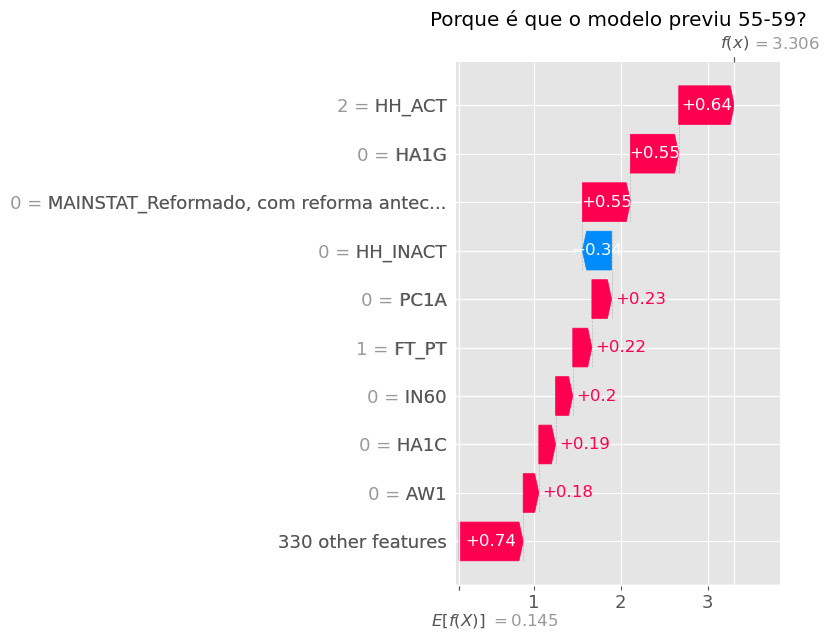

In [9]:
# a) "Sem resposta" no bloco de autonomia: a pergunta foi feita, logo a pessoa tem 55+
BLOCO_55 = ['HA1A', 'HA1B', 'HA1C', 'HA1D', 'HA1E', 'HA1F', 'HA1G', 'PC1A', 'PC1B', 'PC1C', 'PC1D', 'PC1E', 'IN15']
sem_resposta_55 = (X[BLOCO_55] == -2).any(axis=1)
display(pd.crosstab(sem_resposta_55.rename('"Sem resposta" no bloco dos 55'),
                    y.map(lambda f: '55 ou mais' if f >= 9 else 'Menos de 55').rename('Idade')))
artefactos = anomalias_modelo & sem_resposta_55
print(f'Anomalias da 4.2 explicadas por "Sem resposta" no bloco dos 55: {artefactos.sum()} '
      f'(PID {[int(p) for p in X.index[artefactos]]})')

# b) Menopausa declarada antes dos 40
menopausa_cedo = (originais['IN22'] == 'Está na menopausa') & (y <= 4)
print(f'Menopausa declarada antes dos 40: {menopausa_cedo.sum()} '
      f'(PID {[int(p) for p in X.index[menopausa_cedo]]}, faixas {[AGE_LABELS[f] for f in y[menopausa_cedo]]})')

# c) Casos em detalhe
explicar(874, 'Anomalia 1 — 20-24 com menopausa')
explicar(13301, 'Anomalia 2 — 85+ a trabalhar')


> **Conclusão:** as 43 pessoas com "Sem resposta" no bloco de perguntas feitas a partir dos 55 anos têm **todas** 55 ou mais: a resposta prova que a pergunta foi feita. São tão poucas que o modelo não aprendeu este padrão e trata-o como "não perguntado". Por isso, **4 das 36 anomalias da secção 4.2** (PID 10646, 13435, 1265, 13291) são **artefactos do modelo**, e não perfis anómalos.
>
> **PID 874 (20-24, previsto 50-54, confiança 0,92): provável erro de registo.** É a única destas pessoas apanhada tanto por uma regra lógica como pelo modelo. Declara estar na **menopausa** (o sinal mais forte, +1,26), é casada, tem o ensino básico e 3 doenças crónicas. O agregado tem 2 pessoas, mas só ela conta como pessoa com menos de 65 (`HH_ACT = 0`, `HH_INACT = 1`), o que mostra que o **cônjuge tem 65 anos ou mais**. Uma mulher de 20-24 anos na menopausa e casada com alguém de 65+ é possível, mas é muito mais provável que a idade esteja mal registada. Outras 2 pessoas com menos de 40 declaram estar na menopausa (PID 905, 8743).
>
> **PID 13301 (85+, previsto 55-59, confiança 0,64): perfil excecional ou erro de registo.** Homem casado, a trabalhar por conta própria a tempo inteiro, sem doenças crónicas nem dificuldades, num agregado de 4 pessoas com 2 ativas com menos de 65 anos. O modelo sabe que tem 55+ (a pergunta `HA1G` foi feita), mas tudo o resto (trabalhar, não ser reformado, viver com pessoas em idade ativa) é típico de 55-59.
>
> **PID 7191 (50-54, previsto 25-29): pessoa excecional.** Estudante com mestrado, casada, com um filho com menos de 25 anos. Um adulto que regressou aos estudos é um perfil real, mas raro, e o modelo associa "estudante com curso superior" a pessoas jovens.

### 4.4 Lista final de anomalias

Juntamos as anomalias das secções 4.1 a 4.3 numa só tabela e classificamos cada pessoa:
- **provável erro de registo:** viola uma regra impossível, ou é sinalizada por dois métodos independentes (uma regra lógica **e** o modelo);
- **artefacto do modelo:** só o modelo a sinaliza, e a causa é a resposta "Sem resposta" no bloco dos 55 anos;
- **perfil excecional:** sinalizada por um só método (uma regra "muito improvável" ou "rara", ou só o modelo). O perfil é invulgar para a idade, mas pode ser real.

A menopausa declarada antes dos 40 é acrescentada às regras como "muito improvável" (a menopausa precoce existe, mas é rara). A lista completa é guardada em `anomalias_nb04.csv`.


In [10]:
REGRAS['Menopausa declarada antes dos 40'] = ('Muito improvável', menopausa_cedo)

# Motivos de cada pessoa (todas as regras que viola + o modelo)
motivos = pd.Series('', index=X.index)
for regra, (gravidade, mascara) in REGRAS.items():
    motivos[mascara] += regra + ' (' + gravidade.lower() + '); '
motivos[anomalias_modelo] += f'Modelo: P_DECLARADA < {LIMIAR_ANOMALIA}; '

impossivel = pd.Series(False, index=X.index)
regra_qualquer = pd.Series(False, index=X.index)
for regra, (gravidade, mascara) in REGRAS.items():
    regra_qualquer |= mascara
    if gravidade == 'Impossível':
        impossivel |= mascara

# Classificação (da menos para a mais grave: cada linha pode substituir a anterior)
tipo = pd.Series('', index=X.index)
tipo[regra_qualquer | anomalias_modelo] = 'Perfil excecional'
tipo[impossivel | (regra_qualquer & anomalias_modelo)] = 'Provável erro de registo'
tipo[artefactos & ~regra_qualquer] = 'Artefacto do modelo'

anomalias = pd.DataFrame({'Real': [AGE_LABELS[f] for f in y], 'Previsto': [AGE_LABELS[f] for f in oof['PREVISTO']],
                          'P_DECLARADA': oof['P_DECLARADA'].round(3), 'Tipo': tipo, 'Motivos': motivos.str.rstrip('; ')},
                         index=X.index)
anomalias = anomalias[anomalias['Tipo'] != ''].sort_values(['Tipo', 'P_DECLARADA'])
anomalias.index = anomalias.index.astype(int)

print(f'Total de pessoas sinalizadas: {len(anomalias)} ({len(anomalias) / len(X) * 100:.2f}%)')
display(anomalias['Tipo'].value_counts().rename('Pessoas').to_frame())
display(anomalias[anomalias['Tipo'] == 'Provável erro de registo'])

anomalias.to_csv(os.path.join(DATA_DIR, 'anomalias_nb04.csv'))
print(f"Lista completa guardada em {os.path.join(DATA_DIR, 'anomalias_nb04.csv')}")


Total de pessoas sinalizadas: 51 (0.47%)


,Pessoas
Tipo,
Perfil excecional,40
Provável erro de registo,7
Artefacto do modelo,4


,Real,Previsto,P_DECLARADA,Tipo,Motivos
PID,,,,,
1293,85+,65-69,0.001,Provável erro de registo,Empregado com 85 ou mais (raro); Modelo: P_DEC...
13301,85+,55-59,0.001,Provável erro de registo,Empregado com 85 ou mais (raro); Modelo: P_DEC...
874,20-24,50-54,0.003,Provável erro de registo,Menopausa declarada antes dos 40 (muito improv...
554,15-17,30-34,0.245,Provável erro de registo,Idade declarada acima da faixa (FAIXA_MINIMA >...
8743,20-24,25-29,0.534,Provável erro de registo,Idade declarada acima da faixa (FAIXA_MINIMA >...
11385,25-29,30-34,0.817,Provável erro de registo,Idade declarada acima da faixa (FAIXA_MINIMA >...
9151,45-49,65-69,0.993,Provável erro de registo,Idade declarada acima da faixa (FAIXA_MINIMA >...


Lista completa guardada em ../data/anomalias_nb04.csv


> **Conclusão:** no total, **51 pessoas (0,47%)** têm um perfil anómalo para a faixa declarada. Ou seja, mais de 99,5% das respostas são coerentes com a idade. Dividem-se assim:
>
> - **7 prováveis erros de registo:**
>   - 4 casos com idades declaradas noutras perguntas que excedem a faixa: tempo desde a última gravidez (PID 9151, 554, 8743) e a `IN26` (PID 11385);
>   - uma mulher de 20-24 na menopausa e casada com alguém de 65+ (PID 874);
>   - duas pessoas de 85+ que trabalham, apanhadas tanto pela regra como pelo modelo (PID 1293, 13301).
>
>   Nestes casos, o mais provável é que a idade (ou a resposta) tenha sido mal registada.
> - **40 perfis excecionais:** sinalizados por um só método. São combinações raras para a idade (jovens de 18-19 com curso superior, adultos que voltaram a estudar, idosos com perfil de pessoa ativa...), mas plausíveis. Não há razão para os considerar erros.
> - **4 artefactos do modelo:** a resposta "Sem resposta" nas perguntas de autonomia levou o modelo a tratá-los como tendo menos de 55. As respostas são coerentes; a falha é do modelo, que nunca aprendeu esse padrão (raro).
>
> A lista completa, com os motivos de cada pessoa, está em `anomalias_nb04.csv`. Os erros de registo afetam tão poucas pessoas (0,06%) que removê-las do treino não teria efeito mensurável no modelo. Por isso, foram mantidas.

## 5. Caracterização das Faixas Etárias

### 5.1 Perfil de cada faixa

Para caracterizar cada faixa etária, calculamos 18 indicadores simples:
- **demografia e família:** % de mulheres, solteiros, casados, viúvos;
- **escolaridade e trabalho:** % com ensino superior, estudantes, empregados, reformados;
- **agregado:** % a viver sozinho, % com crianças com menos de 14 anos, tamanho médio;
- **saúde:** % com saúde boa ou muito boa, % com dificuldades no dia a dia, nº médio de doenças crónicas, IMC médio;
- **hábitos:** % que fuma diariamente, % que bebe álcool diariamente, % que pratica desporto.

No heatmap, os números são os valores reais e a cor é relativa a cada linha (do mínimo, amarelo, ao máximo, vermelho escuro), para se ver em que idades cada indicador atinge os valores mais altos e mais baixos.


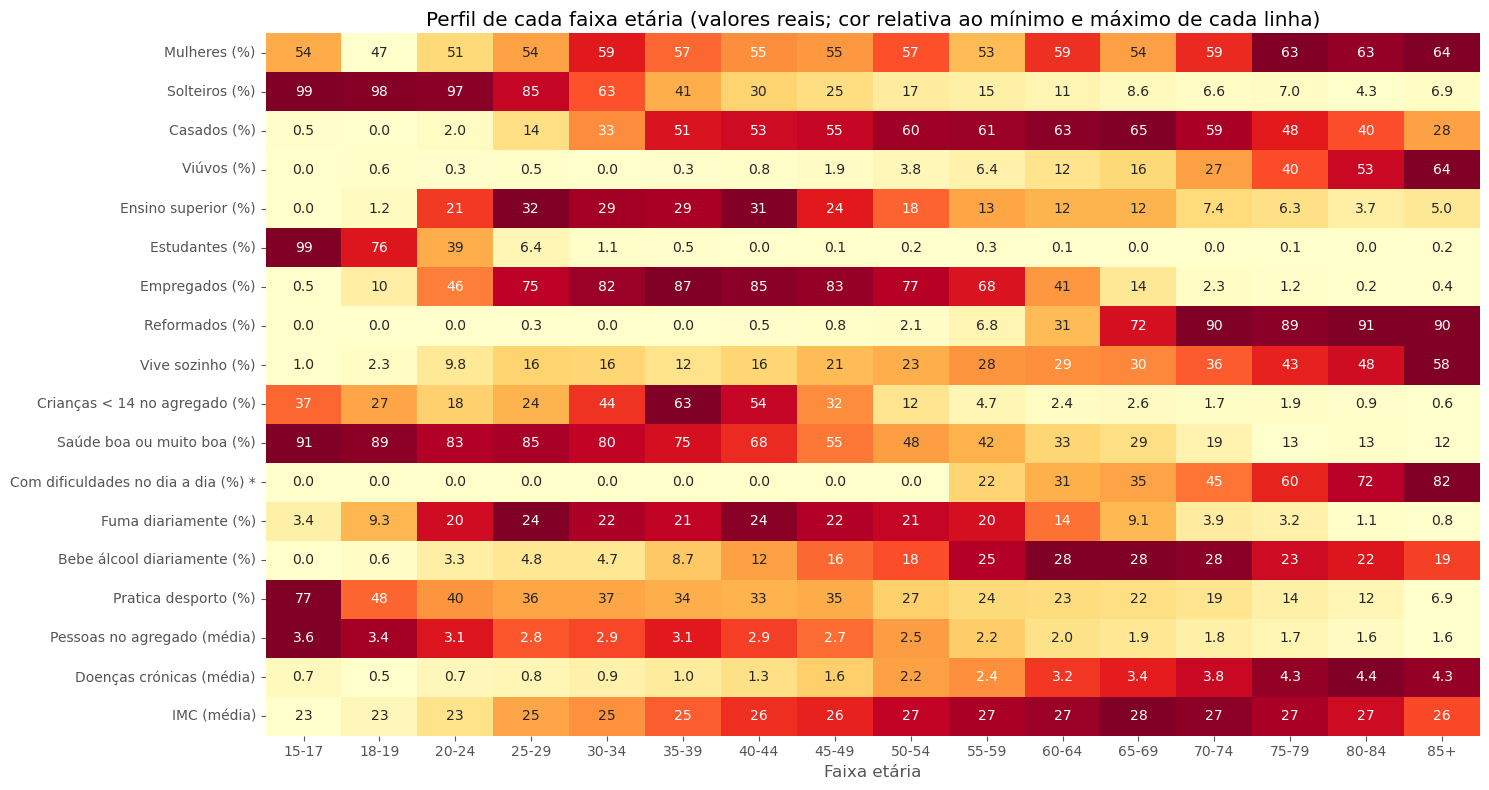

* Perguntas de autonomia só feitas a partir dos 55 anos.


In [11]:
SUPERIOR = ['Bacharelato ou licenciatura 1º ciclo', 'Licenciatura pré-bolonha ou mestrado 2º ciclo', 'Doutoramento']
indicadores = pd.DataFrame({
    'Mulheres (%)': originais['SEX'] == 'Mulher',
    'Solteiros (%)': originais['MARSTALEGAL'] == 'Solteiro',
    'Casados (%)': originais['MARSTALEGAL'] == 'Casado',
    'Viúvos (%)': originais['MARSTALEGAL'] == 'Viúvo',
    'Ensino superior (%)': originais['HATLEVEL'].isin(SUPERIOR),
    'Estudantes (%)': originais['MAINSTAT'].str.startswith('Aluno'),
    'Empregados (%)': originais['MAINSTAT'].str.startswith('Tem um emprego'),
    'Reformados (%)': originais['MAINSTAT'].str.startswith('Reformado'),
    'Vive sozinho (%)': originais['HHTYPE'] == 'Agregado unipessoal',
    'Crianças < 14 no agregado (%)': X['HHNBPERS_0_13_COD'] > 0,
    'Saúde boa ou muito boa (%)': originais['HS1'].isin(['Bom', 'Muito bom']),
    'Com dificuldades no dia a dia (%) *': X['N_DIFICULDADES'] > 0,
    'Fuma diariamente (%)': originais['IN43'] == 'Fuma diariamente',
    'Bebe álcool diariamente (%)': originais['AL1'] == 'Todos os dias ou quase todos os dias',
    'Pratica desporto (%)': X['PE7'] > 0,
}).astype(float) * 100
indicadores['Pessoas no agregado (média)'] = X['HHNBPERS_COD']
indicadores['Doenças crónicas (média)'] = X['N_DOENCAS']
indicadores['IMC (média)'] = X['IMC'].where(X['IMC'] > 0)                # -1 = sem altura/peso

perfil = indicadores.groupby(y).mean().T
perfil.columns = AGE_LABELS

# Cores por linha: mostram em que faixas cada indicador é mais alto (0 = mínimo da linha, 1 = máximo)
cores = perfil.sub(perfil.min(axis=1), axis=0).div(perfil.max(axis=1) - perfil.min(axis=1), axis=0)
textos = perfil.map(lambda v: f'{v:.1f}' if v < 10 else f'{v:.0f}')     # 1 casa decimal nos valores pequenos
plt.figure(figsize=(15, 8))
sns.heatmap(cores, annot=textos, fmt='', cmap='YlOrRd', cbar=False)
plt.title('Perfil de cada faixa etária (valores reais; cor relativa ao mínimo e máximo de cada linha)')
plt.xlabel('Faixa etária')
plt.ylabel('')
plt.tight_layout()
plt.show()
print('* Perguntas de autonomia só feitas a partir dos 55 anos.')


> **Conclusão:** os indicadores mudam com a idade de forma muito regular e marcam claramente as grandes etapas da vida:
> - **Estudo → trabalho → reforma:** os estudantes passam de 99% (15-17) para 39% (20-24) e quase desaparecem a partir dos 30. Os empregados atingem o máximo entre os 35 e os 49 (83–87%) e caem a pique entre os 60 e os 69 (41% → 14%), à medida que os reformados sobem de 31% para 72%. A partir dos 70, cerca de 90% estão reformados.
> - **Família:** os solteiros são a maioria até aos 29 (85%). Os casados passam a ser maioria a partir dos 35 e atingem o máximo nos 65-69 (65%). Depois, a viuvez cresce rapidamente: 27% aos 70-74 e **64% aos 85+**. Ter crianças com menos de 14 anos em casa é mais comum entre os 30 e os 44 (pico de 63% aos 35-39). O agregado vai encolhendo de 3,6 pessoas (15-17, ainda com os pais) para 1,6 (80+), e viver sozinho passa de 1% para **58%** nos 85+.
> - **Escolaridade:** o ensino superior é mais frequente entre os 25 e os 44 (~30%) e muito raro acima dos 75 (≤ 6%). Reflete as gerações, e não a idade em si: as pessoas mais velhas estudaram numa época com menos acesso ao ensino superior.
> - **Saúde:** a saúde autoavaliada como boa ou muito boa cai de 91% (15-17) para 12% (85+). O número médio de doenças crónicas sobe de 0,7 para 4,3. A partir dos 55, as dificuldades no dia a dia crescem de 22% para 82%. O IMC sobe até aos 65-69 (27,5) e desce ligeiramente nas idades mais avançadas.
> - **Hábitos:** o tabaco diário concentra-se entre os 20 e os 59 (20–24%) e quase desaparece depois dos 75. O álcool diário segue o padrão inverso: cresce com a idade e atinge o máximo entre os 60 e os 74 (28%). O desporto é máximo na adolescência (77%) e cai continuamente até 7% nos 85+.
>
> As mulheres são maioria em quase todas as faixas, sobretudo a partir dos 75 (63–64%), o que reflete a maior esperança de vida feminina.


### 5.2 Quão reconhecível é cada faixa

O perfil da secção 5.1 descreve cada faixa; falta saber quão **distinta** ela é das restantes. Usando as previsões fora da amostra do modelo (secção 2), calculamos para cada faixa o F1, a percentagem de acerto exato, a percentagem de previsões a no máximo uma faixa de distância e a faixa com que é mais confundida. Uma faixa com perfil muito próprio é reconhecida com facilidade; uma faixa com perfil semelhante às vizinhas é confundida com elas.


In [12]:
matriz = confusion_matrix(oof['REAL'], oof['PREVISTO'], labels=range(16))
reconhecimento = []
for k, faixa in enumerate(AGE_LABELS):
    linha = matriz[k].copy()
    acertos = linha[k]
    linha[k] = 0                                                   # ignora os acertos para achar o erro mais comum
    reconhecimento.append({'Faixa': faixa,
                           'F1': f1_score(oof['REAL'], oof['PREVISTO'], labels=[k], average='macro'),
                           'Acerto (%)': acertos / matriz[k].sum() * 100,
                           'A ≤ 1 faixa (%)': matriz[k, max(0, k - 1):k + 2].sum() / matriz[k].sum() * 100,
                           'Mais confundida com': AGE_LABELS[linha.argmax()],
                           '% confundida': linha.max() / matriz[k].sum() * 100})
display(pd.DataFrame(reconhecimento).set_index('Faixa').round(2))


,F1,Acerto (%),A ≤ 1 faixa (%),Mais confundida com,% confundida
Faixa,,,,,
15-17,0.86,89.37,97.58,18-19,8.21
18-19,0.47,44.77,97.67,20-24,34.88
20-24,0.63,62.91,90.98,18-19,14.79
25-29,0.43,44.56,84.62,30-34,25.73
30-34,0.33,35.86,85.52,35-39,28.06
35-39,0.38,40.96,85.63,40-44,24.57
40-44,0.39,39.23,82.77,35-39,23.86
45-49,0.42,39.21,85.73,40-44,25.87
50-54,0.67,63.65,86.63,45-49,22.98


> **Conclusão:** a facilidade em reconhecer cada faixa depende de quão próprio é o seu perfil e de existirem ou não "cortes" nas respostas. Juntando o perfil (5.1), a importância das variáveis (3.2) e o reconhecimento (5.2), as faixas agrupam-se em sete retratos:
>
> | Grupo | Retrato típico | Reconhecimento |
> |---|---|---|
> | **15-17** (adolescentes) | Estudantes (99%), solteiros, a viver com os pais em agregados grandes (3,6 pessoas), escolaridade ainda no 3.º ciclo, saúde muito boa (91%), muito ativos no desporto (77%), quase sem tabaco nem álcool. | **O mais fácil** (F1 0,86; 89% de acerto): o perfil "estudante do básico" é exclusivo desta faixa. |
> | **18-24** (jovens adultos em transição) | Ainda maioritariamente estudantes aos 18-19 (76%), mas a meio da transição para o trabalho aos 20-24 (46% empregados, 39% estudantes); solteiros (97%); o ensino superior começa a aparecer (21%); o tabaco diário sobe para 20%. | 18-19 é muito confundida com 20-24 (35%), porque partilham o mesmo perfil; 20-24 é mais fácil (F1 0,63) por ser a faixa onde se concentram os estudantes do ensino superior. |
> | **25-49** (idade ativa e família) | Empregados (75–87%), casamento a tornar-se maioritário a partir dos 35, crianças pequenas em casa (pico de 63% aos 35-39), a maior percentagem de ensino superior (~30%), o máximo de tabaco diário (21–24%) e saúde ainda boa mas em queda (85% → 55%). | **O grupo mais difícil** (F1 0,33–0,43): em 25 anos, o perfil muda pouco de faixa para faixa, e não há perguntas que mudem nestas idades. Cada faixa é confundida com as vizinhas em ~25%. |
> | **50-54** (antes dos 55) | Ainda empregados (77%), casados (60%), filhos já crescidos (só 12% com crianças), primeiras doenças crónicas (2,2) e saúde boa em apenas 48%; menopausa nas mulheres. | Mais fácil do que as anteriores (F1 0,67), porque é a **última faixa antes do corte dos 55**: quem tem perfil "envelhecido" mas não recebeu as perguntas de autonomia fica aqui. |
> | **55-64** (pré-reforma) | Transição do trabalho para a reforma (68% → 41% empregados; 7% → 31% reformados), casados (61–63%), álcool diário a subir (25–28%), as primeiras dificuldades no dia a dia (22–31%). | **Quase nunca há erros grandes** (98,6% e 99,7% a ≤ 1 faixa): estão encaixadas entre os **dois cortes perfeitos** (55, perguntas de autonomia; 65, deixar de contar no `HH_ACT`/`HH_INACT`). O modelo só hesita entre as duas. |
> | **65-74** (reforma recente) | Reformados (72–90%), ainda maioritariamente casados (59–65%), a viuvez a crescer (16% → 27%), o máximo de álcool diário (28%), 3,4–3,8 doenças crónicas e dificuldades em 35–45%. | 65-69 é razoável (F1 0,56), por ficar logo a seguir ao corte dos 65; 70-74 já se confunde com 75-79 (30%). |
> | **75+** (idade avançada) | Reformados (~90%), cada vez mais viúvos (40% → 64%) e a viver sozinhos (43% → 58%), maioria feminina (63%), saúde boa em apenas 12–13%, 4,3 doenças crónicas, dificuldades no dia a dia em 60–82%, tabaco e desporto quase inexistentes. | Difícil de separar internamente (F1 0,33–0,50): depois da reforma não há nenhuma etapa da vida que marque uma idade concreta, e o envelhecimento é gradual e muito diferente de pessoa para pessoa. A 85+ é mais reconhecível (0,50) por ser o extremo, com o máximo de viuvez e de dificuldades. |
>
> Em resumo, o modelo reconhece bem as faixas que coincidem com **etapas bem definidas da vida** (estudante, pré-reforma) ou com **regras do questionário** (55 e 65 anos), e tem mais dificuldade nos períodos longos e estáveis: a idade ativa (25-49) e a velhice (70+).


## 6. Conclusões

**Interpretabilidade (secção 3)**
- As variáveis mais importantes refletem as **etapas da vida**: situação principal (`MAINSTAT`: estudante → empregado → reformado), estado civil (`MARSTALEGAL`), composição do agregado (`HH_ACT`, `HH_INACT`, `HHTYPE`) e escolaridade (`HATLEVEL`).
- O questionário tem **dois cortes por idade** que o modelo explora:
  - **aos 55 anos**, as perguntas de autonomia (`HA1*`, `PC1*`, `IN15`) só são feitas a partir desta idade. Juntas, valem cerca de 28% da importância total;
  - **aos 65 anos**, as variáveis `HH_ACT` e `HH_INACT` contam só os membros do agregado com menos de 65 anos. Por isso, quando ambas são 0, a pessoa tem 65+ (3202 pessoas, com apenas 2 exceções).
- As variáveis criadas no Notebook 2 contribuem: a `IDADE_MINIMA` está entre as 15 mais importantes e a `N_DIFICULDADES` é o principal sinal dos 85+.
- Em cada fronteira do modelo ordinal, os sinais mudam: escola e estado civil aos 20; perguntas de autonomia aos 55; agregado e reforma aos 65; dificuldades e viuvez aos 80.

**Deteção de anomalias (secção 4)**
- 51 pessoas (0,47%) têm um perfil anómalo para a faixa declarada; mais de 99,5% das respostas são coerentes com a idade.
- **7 prováveis erros de registo:** idades declaradas noutras perguntas incompatíveis com a faixa (ex.: última gravidez há 50 anos numa pessoa de 45-49), menopausa aos 20-24, pessoas de 85+ a trabalhar a tempo inteiro sinalizadas por dois métodos.
- **40 perfis excecionais:** combinações raras mas plausíveis (adultos que voltaram a estudar, idosos com perfil de pessoa ativa).
- **4 artefactos do modelo:** a resposta "Sem resposta" nas perguntas de autonomia prova que a pessoa tem 55+, mas é tão rara que o modelo não a aprendeu.
- As regras lógicas e o modelo são complementares: só 2 pessoas foram apanhadas pelos dois métodos.

**Caracterização das faixas (secção 5)**
- **15-17:** estudantes, com saúde e atividade física no máximo; a faixa mais fácil de reconhecer (F1 0,86).
- **18-24:** a transição do estudo para o trabalho; 18-19 confunde-se muito com 20-24.
- **25-49:** idade ativa e família (emprego, casamento, crianças pequenas). É o período mais difícil de distinguir (F1 0,33–0,43), porque o perfil muda pouco durante 25 anos.
- **55-64:** a pré-reforma, encaixada entre os cortes dos 55 e dos 65 (≥ 98,6% das previsões a ≤ 1 faixa).
- **65+:** reforma, viuvez crescente, mais doenças e dificuldades. É difícil separar as faixas entre si, porque o envelhecimento é gradual e heterogéneo.

**Limitações**
- A interpretabilidade foi feita sobre um XGBoost de 16 faixas (Macro F1 0,480) e sobre modelos binários isolados do modelo ordinal, e não sobre o modelo final completo (165 modelos). As variáveis importantes são as mesmas, mas a ordem pode variar ligeiramente.
- As variáveis que contêm a mesma informação (as perguntas do corte dos 55) repartem a importância entre si. A importância de cada uma isoladamente subestima a do bloco.
- A classificação das anomalias usa regras de bom senso e um limiar (5%) escolhidos por nós; outros limiares dariam listas ligeiramente diferentes. Sem acesso às idades exatas, não é possível confirmar quais são, de facto, erros de registo.
